# 03 - Imitation Learning

## Imports

In [1]:
import heapq
import warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)   # numpy on some Macs warns spuriously inside matmul

# Make sure we get outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)

## When You Have a Teacher Instead of a Reward

`01` and `02` learned from reward alone. Nobody told the agent which pick was correct, it only saw numbers come back and had to work out the rest. That is the hard way to learn, and for a lot of robot problems it is also the hard way to set up. Recall `01`'s reward design section spent a whole section on how easily a reward function goes wrong.

Often there is an easier source of signal. A human driver can teleoperate the robot through the task a few dozen times. A planner we already trust, like the A\* from `perception_primer/09`, can produce a good path from any position. Either one gives us **demonstrations**, or pairs of (state, the action the expert took there). **Imitation Learning** is learning a policy from demonstrations instead of from reward.

The simplest version is **Behavior Cloning**. Treat the expert's action as the label, and train the policy network with supervised learning. There is no environment loop, no exploration, and no reward. This is the same setup as `ml_primer`'s classifiers, with a robot's state as the input and an action as the class.

## The World

We'll use a small grid. The robot starts near the bottom-left corner and needs to reach the goal in the top-right. Two walls sit in between, so there is no straight line to the goal. The robot can move in any of 8 directions each step.

The expert is `perception_primer/09`'s A\*. Our expert is a function we can call on any cell, not just a fixed set of recorded paths. A human driver can't do that (you can't ask them what they would have done in a situation they never drove through), but a planner can.

We only collect demonstrations from a small 3x3 patch of starting cells in the bottom-left corner.

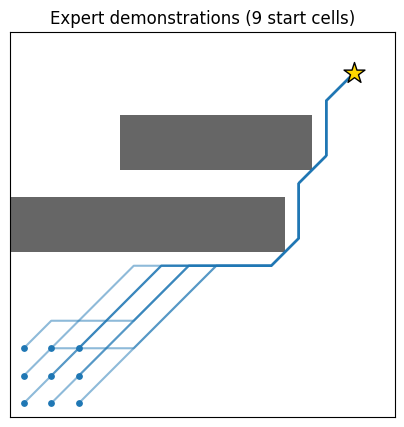

In [2]:
N = 14
grid = np.zeros((N, N))
grid[6:8, 0:10] = 1      # first wall, gap on the right
grid[9:11, 4:11] = 1     # second wall, open at both ends
GOAL = (12, 12)

# (row, col) moves: up, down, left, right, then the four diagonals
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def a_star(grid, start_cell, goal_cell):
    """ Same A* as perception_primer/09, on (row, col) cells. Returns the list of cells or None. """
    h, w = grid.shape

    def heuristic(a, b):
        return np.hypot(a[0] - b[0], a[1] - b[1])

    def neighbors(cell):
        r, c = cell
        for dr, dc in ACTIONS:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and grid[nr, nc] == 0:
                yield (nr, nc), np.hypot(dr, dc)

    open_set = [(heuristic(start_cell, goal_cell), 0.0, start_cell)]
    came_from = {}
    cost_so_far = {start_cell: 0.0}
    while open_set:
        _, g, current = heapq.heappop(open_set)
        if current == goal_cell:
            path = [current]
            while path[-1] in came_from:
                path.append(came_from[path[-1]])
            return path[::-1]
        for neighbor, step_cost in neighbors(current):
            new_cost = g + step_cost
            if neighbor not in cost_so_far or new_cost < cost_so_far[neighbor]:
                cost_so_far[neighbor] = new_cost
                heapq.heappush(open_set, (new_cost + heuristic(neighbor, goal_cell), new_cost, neighbor))
                came_from[neighbor] = current
    return None

def expert_action(cell, goal=GOAL, world=None):
    """ The expert's action index from ANY cell: the first step of a fresh A* plan. """
    path = a_star(grid if world is None else world, cell, goal)
    if path is None or len(path) < 2:
        return None
    return ACTIONS.index((path[1][0] - cell[0], path[1][1] - cell[1]))

def step(cell, action, world=None):
    """ Move one cell. Bumping a wall or the field edge leaves the robot where it was. """
    world = grid if world is None else world
    nr, nc = cell[0] + ACTIONS[action][0], cell[1] + ACTIONS[action][1]
    if 0 <= nr < N and 0 <= nc < N and world[nr, nc] == 0:
        return (nr, nc)
    return cell

demo_starts = [(r, c) for r in range(3) for c in range(3)]
demo_paths = [a_star(grid, s, GOAL) for s in demo_starts]

def draw_world(ax, title):
    ax.imshow(grid, origin="lower", cmap="Greys", alpha=0.6)
    ax.scatter([GOAL[1]], [GOAL[0]], marker="*", s=250, color="gold", edgecolor="black", zorder=5)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

fig, ax = plt.subplots(figsize=(5, 5))
draw_world(ax, "Expert demonstrations (9 start cells)")
for p in demo_paths:
    ax.plot([c for r, c in p], [r for r, c in p], "-", color="tab:blue", alpha=0.5)
ax.scatter([c for r, c in demo_starts], [r for r, c in demo_starts], color="tab:blue", s=15)
plt.show()

The nine paths funnel through the same two gaps. Everything the student will see during training lives in a narrow band along those lines, which will matter in a moment.

## Behavior Cloning Is Classification

The student is a Policy Network like the one in `02`. There are two input features (where the robot is on the grid, scaled to roughly -1 to 1), a hidden ReLU layer, and 8 output logits through a softmax, one per direction.

Training is where `02`'s observation pays off. There, the policy gradient update was a classification loss scaled by how much better than expected the reward was:

$$ \text{Loss} = -(\text{reward} - \text{baseline}) \cdot \log \pi(a) $$

Here the label is the expert's action, and we want the policy to match it every time, so the scaling factor is just 1. The loss is plain cross-entropy, and the gradient with respect to the logits is the same $\pi - \text{onehot}(a)$.

In [3]:
def features(cell):
    """ Position on the grid, scaled to roughly -1..1. Shape (2, 1). """
    return np.array([[(cell[0] - 6.5) / 6.5], [(cell[1] - 6.5) / 6.5]])

def relu(z):
    return np.maximum(0, z)

class PolicyNet:
    """ 2 -> hidden ReLU layer -> 8 logits -> softmax, same body as the policy network in 02. """
    def __init__(self, hidden=48):
        self.W1 = np.random.randn(hidden, 2) * 0.8
        self.b1 = np.random.randn(hidden, 1) * 0.3
        self.W2 = np.random.randn(8, hidden) * 0.3
        self.b2 = np.zeros((8, 1))

    def forward(self, X):
        z1 = self.W1 @ X + self.b1
        a1 = relu(z1)
        logits = self.W2 @ a1 + self.b2
        logits = logits - logits.max(axis=0)       # for numerical stability
        probs = np.exp(logits) / np.exp(logits).sum(axis=0)
        return z1, a1, probs

    def fit(self, X, labels, learning_rate=0.05, steps=4000):
        n = X.shape[1]
        onehot = np.eye(8)[:, labels]
        for _ in range(steps):
            z1, a1, probs = self.forward(X)
            d_logits = (probs - onehot) / n          # the pi - onehot(a) gradient from 02
            d_W2 = d_logits @ a1.T
            d_b2 = d_logits.sum(axis=1, keepdims=True)
            d_z1 = (self.W2.T @ d_logits) * (z1 > 0)
            self.W1 -= learning_rate * d_z1 @ X.T
            self.b1 -= learning_rate * d_z1.sum(axis=1, keepdims=True)
            self.W2 -= learning_rate * d_W2
            self.b2 -= learning_rate * d_b2
        return (probs.argmax(axis=0) == labels).mean()

    def act(self, cell):
        return int(self.forward(features(cell))[2].argmax())

def demos_from_paths(paths):
    cells, actions = [], []
    for p in paths:
        for a, b in zip(p[:-1], p[1:]):
            cells.append(a)
            actions.append(ACTIONS.index((b[0] - a[0], b[1] - a[1])))
    return cells, actions

demo_cells, demo_actions = demos_from_paths(demo_paths)
X_demo = np.hstack([features(c) for c in demo_cells])
y_demo = np.array(demo_actions)

bc_policy = PolicyNet()
bc_accuracy = bc_policy.fit(X_demo, y_demo)
print(f"{X_demo.shape[1]} demonstration steps, accuracy on them: {bc_accuracy:.1%}")

135 demonstration steps, accuracy on them: 95.6%


The student matches the expert on nearly every demonstrated state. In supervised learning, that would be the end of the story. But a policy is not scored on how well it matches labels, it is scored on whether the robot reaches the goal when it drives itself, and when it drives itself it generates its own states.

To test that, we run the student for real. We also let the environment misbehave a little. With probability `slip`, the robot's chosen move is swapped for a random one, the way wheel slip, a bumped robot, or a bad odometry reading would. We start the student from the same 9 corner cells it was trained on, and separately from every free cell on the field.

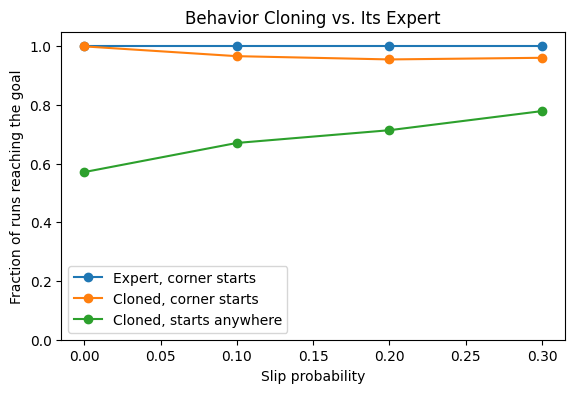

Expert, corner starts      1.00  1.00  1.00  1.00
Cloned, corner starts      1.00  0.97  0.96  0.96
Cloned, starts anywhere    0.57  0.67  0.71  0.78


In [4]:
def rollout(act_fn, start, slip=0.0, max_steps=70):
    """ Drive from `start` with a policy. Returns the list of cells visited. """
    cell = start
    visited = [cell]
    for _ in range(max_steps):
        if cell == GOAL:
            break
        action = np.random.randint(8) if np.random.rand() < slip else act_fn(cell)
        cell = step(cell, action)
        visited.append(cell)
    return visited

def success_rate(act_fn, starts, slip=0.0, reps=1):
    return np.mean([rollout(act_fn, s, slip)[-1] == GOAL for s in starts for _ in range(reps)])

free_cells = [(r, c) for r in range(N) for c in range(N) if grid[r, c] == 0 and (r, c) != GOAL]
expert_fn = lambda cell: expert_action(cell)

slips = [0.0, 0.1, 0.2, 0.3]
results = {
    "Expert, corner starts":     [success_rate(expert_fn, demo_starts, s, reps=5) for s in slips],
    "Cloned, corner starts":     [success_rate(bc_policy.act, demo_starts, s, reps=20) for s in slips],
    "Cloned, starts anywhere":   [success_rate(bc_policy.act, free_cells, s, reps=2) for s in slips],
}

plt.figure(figsize=(6.5, 4))
for label, vals in results.items():
    plt.plot(slips, vals, "o-", label=label)
plt.xlabel("Slip probability")
plt.ylabel("Fraction of runs reaching the goal")
plt.ylim(0, 1.05)
plt.legend()
plt.title("Behavior Cloning vs. Its Expert")
plt.show()

for label, vals in results.items():
    print(f"{label:26s}", "  ".join(f"{v:.2f}" for v in vals))

Two things stand out. The expert stays at 1.00 at every slip level, because it re-plans from wherever it ends up, so there is no state it can be pushed into that it has no answer for. The cloned policy is nearly as good from the corner starts (around 0.96 at worst), so on this field, small nudges don't hurt it much.

The "starts anywhere" line is the problem. With no slip at all, only about 57% of runs reach the goal, using the same network that matched the expert on about 96% of its training steps. That line rises a little as slip goes up, and the reason is a funny one: random moves sometimes knock the robot back onto the demonstrated band.

## Why It Fails: Distribution Shift

Every training example came from the expert's own states. At test time the student sees states produced by its own behavior, and the two distributions are not the same. Any small mistake pushes the student somewhere the expert never went, so there are no labels for what to do next. It guesses, usually badly, and the guess pushes it further out. 

Errors compound instead of averaging out, which is called **Distribution Shift** (or covariate shift) and is the defining weakness of behavior cloning. Ross et al. (2011), linked below, show that the cost of a small per-step error grows with the square of the episode length for this reason, where an ordinary supervised model would only pay it linearly.

The "starts anywhere" line is the cleanest way to see it. Cells off the demonstrated band are the states a slip or a bump would leave the robot in, and the student has no idea what to do in many of them. Here is where the cloned policy sends the robot from a handful of those cells:

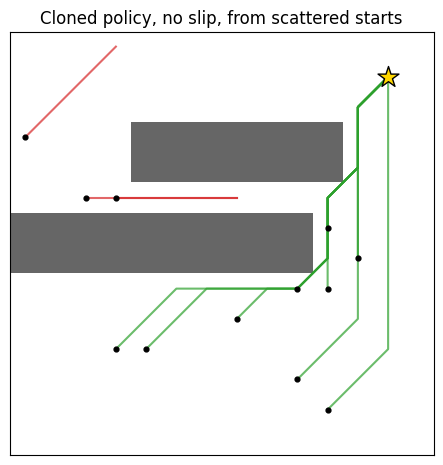

In [5]:
np.random.seed(7)
sample_starts = [free_cells[i] for i in np.random.choice(len(free_cells), 12, replace=False)]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_world(ax, "Cloned policy, no slip, from scattered starts")
for s in sample_starts:
    path = rollout(bc_policy.act, s)
    reached = path[-1] == GOAL
    ax.plot([c for r, c in path], [r for r, c in path], "-", color="tab:green" if reached else "tab:red", alpha=0.7)
    ax.scatter([s[1]], [s[0]], color="black", s=12, zorder=4)
plt.show()

Green runs reach the goal and red runs don't. Look at the failures: one run in the top-left heads off diagonally into the edge of the field, and one in the lane between the two walls drives straight right until it presses against a wall. Neither start is near any demonstration, so the network is extrapolating from whichever training examples happen to be closest. The expert would have re-planned from either cell.

## DAgger: Let the Student Drive, Let the Expert Label

The fix follows from the diagnosis. The student is missing labels for the states it actually visits, so go get them. **DAgger** (Dataset Aggregation) does this in rounds:

1. Roll out the current student and record every state it visits, including the bad ones.
2. Ask the expert what it would have done in each of those states.
3. Add those (state, expert action) pairs to the dataset, and retrain on everything collected so far.

The expert is being asked to label states that the student drove into, not states the expert would have chosen. That is why it matters that our A\* expert can answer from any cell. With a human expert this step is much more awkward, since they would have to look at a recorded situation and say what they would have done, rather than doing it live.

We collect with the slip turned up to 0.3, so the student gets pushed into plenty of off-path states to learn from.

round 1: 1406 labeled states


round 2: 2344 labeled states


round 3: 3317 labeled states


round 4: 4349 labeled states


round 5: 5401 labeled states


round 6: 6475 labeled states


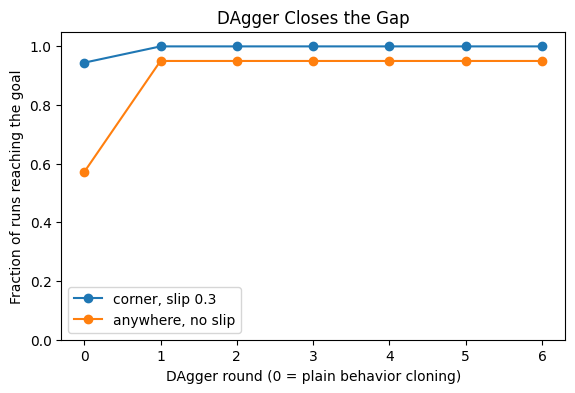

In [6]:
np.random.seed(1515)
X_all, y_all = X_demo.copy(), y_demo.copy()
student = bc_policy

history = {"corner, slip 0.3": [success_rate(student.act, demo_starts, 0.3, reps=20)],
           "anywhere, no slip": [success_rate(student.act, free_cells, 0.0, reps=2)]}

for dagger_round in range(1, 7):
    new_X, new_y = [], []
    for s in demo_starts:
        for _ in range(5):
            for cell in rollout(student.act, s, slip=0.3):
                if cell != GOAL:
                    new_X.append(features(cell))
                    new_y.append(expert_action(cell))      # the expert labels the student's states
    X_all = np.hstack([X_all] + new_X)
    y_all = np.concatenate([y_all, new_y])

    student = PolicyNet()
    student.fit(X_all, y_all)
    history["corner, slip 0.3"].append(success_rate(student.act, demo_starts, 0.3, reps=20))
    history["anywhere, no slip"].append(success_rate(student.act, free_cells, 0.0, reps=2))
    print(f"round {dagger_round}: {X_all.shape[1]} labeled states")

plt.figure(figsize=(6.5, 4))
for label, vals in history.items():
    plt.plot(range(len(vals)), vals, "o-", label=label)
plt.xlabel("DAgger round (0 = plain behavior cloning)")
plt.ylabel("Fraction of runs reaching the goal")
plt.ylim(0, 1.05)
plt.legend()
plt.title("DAgger Closes the Gap")
plt.show()

dagger_policy = student

One round is enough here. From the corner starts with slip 0.3, the cloned policy goes from about 0.94 to 1.00. More interesting is the "starts anywhere" line, which jumps from about 0.57 to about 0.95 even though every DAgger rollout began at a corner start. The states those rollouts wandered into, with slip knocking them off the path, were enough to teach the student what to do across most of the field.

The cost is labels. The final dataset has roughly 6,500 expert-labeled states, against 135 from the original demonstrations, so DAgger used about 50 times as many expert queries. This is a large scale factor, so be aware that to use this, you need access to a lot of data! 

## Many Experts, One Average

There is a second way behavior cloning fails. This one is `genai_architecture_primer/08`'s multimodality problem.

Suppose the field has a single block directly between the robot and its goal, and our demonstrations come from two human drivers. One always goes around the left side, the other always goes around the right. Both are perfectly good experts. But if the policy outputs a single action and we train it with a regression loss on the demonstrated actions, then at the decision point it sees "half the time go up-left, half the time go up-right" and the loss-minimizing answer is the average, which is straight up, into the block.

A classification head does not have this problem. It can put 50% on up-left and 50% on up-right, and sampling picks one. We'll train both on the same demonstrations and drive them.

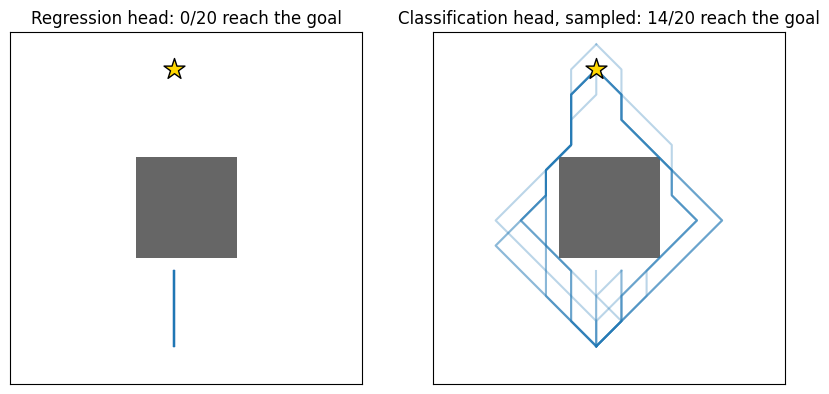

In [7]:
grid2 = np.zeros((N, N))
grid2[5:9, 5:9] = 1                        # one block between the robot and the goal
GOAL2 = (12, 6)

def drive_via(world, start, waypoint, goal):
    """ A demonstration: A* to a waypoint beside the block, then A* on to the goal. """
    return a_star(world, start, waypoint)[:-1] + a_star(world, waypoint, goal)

np.random.seed(1515)
two_driver_paths = []
for _ in range(30):
    start = (1, 6)                       # both drivers start from the same cell
    two_driver_paths.append(drive_via(grid2, start, (6, 3), GOAL2))     # the left-hand driver
    two_driver_paths.append(drive_via(grid2, start, (6, 10), GOAL2))    # the right-hand driver

cells2, actions2 = demos_from_paths(two_driver_paths)
X2 = np.hstack([features(c) for c in cells2])
y2 = np.array(actions2)

# classification head: reuse PolicyNet as it is
class_policy = PolicyNet(hidden=128)
class_policy.fit(X2, y2, steps=8000)

# regression head: same body, but it outputs a (d_row, d_col) move and is trained with squared error
class RegressionPolicy:
    def __init__(self, hidden=128):
        self.W1 = np.random.randn(hidden, 2) * 0.8
        self.b1 = np.random.randn(hidden, 1) * 0.3
        self.W2 = np.random.randn(2, hidden) * 0.3
        self.b2 = np.zeros((2, 1))

    def forward(self, X):
        z1 = self.W1 @ X + self.b1
        a1 = relu(z1)
        return z1, a1, self.W2 @ a1 + self.b2

    def fit(self, X, action_indices, learning_rate=0.05, steps=8000):
        targets = np.array([ACTIONS[a] for a in action_indices], dtype=float).T
        n = X.shape[1]
        for _ in range(steps):
            z1, a1, pred = self.forward(X)
            d_pred = 2 * (pred - targets) / n
            d_z1 = (self.W2.T @ d_pred) * (z1 > 0)
            self.W1 -= learning_rate * d_z1 @ X.T
            self.b1 -= learning_rate * d_z1.sum(axis=1, keepdims=True)
            self.W2 -= learning_rate * d_pred @ a1.T
            self.b2 -= learning_rate * d_pred.sum(axis=1, keepdims=True)

    def act(self, cell):
        move = self.forward(features(cell))[2].ravel()
        return int(np.argmin([np.hypot(move[0] - dr, move[1] - dc) for dr, dc in ACTIONS]))   # snap to nearest move

regress_policy = RegressionPolicy()
regress_policy.fit(X2, y2)

def sampled_act(policy):
    def act(cell):
        probs = policy.forward(features(cell))[2].ravel()
        return int(np.random.choice(8, p=probs))
    return act

def rollout2(act_fn, start, max_steps=60):
    cell, visited = start, [start]
    for _ in range(max_steps):
        if cell == GOAL2:
            break
        cell = step(cell, act_fn(cell), world=grid2)
        visited.append(cell)
    return visited

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, fn) in zip(axes, [("Regression head", regress_policy.act), ("Classification head, sampled", sampled_act(class_policy))]):
    ax.imshow(grid2, origin="lower", cmap="Greys", alpha=0.6)
    ax.scatter([GOAL2[1]], [GOAL2[0]], marker="*", s=250, color="gold", edgecolor="black", zorder=5)
    ok = 0
    for _ in range(20):
        path = rollout2(fn, (1, 6))
        ok += path[-1] == GOAL2
        ax.plot([c for r, c in path], [r for r, c in path], "-", alpha=0.3, color="tab:blue")
    ax.set_title(f"{name}: {ok}/20 reach the goal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

The regression head drives straight at the block and stays there. At the decision point it learned the average of "up-left" and "up-right", which is "up". The classification head reaches the goal by choosing a side, reaching the goal in 14 of 20 runs.

It isn't perfect. Each step the classification head samples fresh from its probabilities, so near the start, where the two drivers' paths overlap, it can wobble between the two modes (you can see the crossing lines under the block). `genai_architecture_primer/08` covers two ways to fix that: diffusion policies, which sample a whole committed trajectory instead of one step at a time, and action tokens, which are this classification approach scaled up.

## Imitation vs. Reinforcement Learning

Neither one replaces the other. They fail in opposite ways.

| | Imitation Learning | Reinforcement Learning |
|---|---|---|
| What it needs | Demonstrations (and, for DAgger, an expert you can query) | A reward function and an environment to try things in |
| Ceiling | The expert. It can match them, it can't beat them | The reward. It can find strategies no expert would |
| Typical failure | Distribution shift in states the expert never visited | Reward hacking, and a huge number of trials |
| Sample cost | Dozens to thousands of demos | Often millions of episodes |

In practice they are combined. A policy is first cloned from demonstrations so it starts out competent, then fine-tuned with RL against a reward to improve past the demonstrations. This is the same shape as `genai_architecture_primer/05`, where instruction fine-tuning is behavior cloning on human-written answers and RLHF then optimizes against a reward model. The imitation step is also what makes the RL step affordable, since a policy that already does something sensible doesn't need millions of random trials to find that.

`06-imitation-then-rl.ipynb` runs this combination and measures what each step does and what can go wrong with it.

For our own robot, the practical version of this is to record the drive team's best matches, clone a policy from them, and you have a starting point that needs far less trial and error than learning from reward alone. The warning from DAgger carries over, too. The first time that policy drives itself, it will meet states your drivers never did.

## Try It Yourself

1. Change the world. Close the gap on the left side of the second wall (`grid[9:11, 4:11]` becomes `grid[9:11, 0:11]`), then re-run behavior cloning from the same 9 corner starts. Does plain cloning get better or worse than before, and why?
2. Count what DAgger costs. Every round labels the states the student visited by calling `expert_action`. Add a counter and report how many expert queries the 6 rounds above used, compared to the number of demonstration steps behavior cloning needed.
3. Break the multimodal result on purpose. Re-train `class_policy` using only the left-hand driver's demonstrations. What happens when it drives, and what does that tell you about how much the classification head's success depends on the demonstrations covering both modes?

In [8]:
# TODO: 1. close the second wall's left gap and re-run behavior cloning from demo_starts

# TODO: 2. count the expert queries DAgger makes across 6 rounds

# TODO: 3. retrain class_policy on only the left-hand driver's demonstrations and drive it

## Resources

- [Ross, Gordon & Bagnell (2011), "A Reduction of Imitation Learning and Structured Prediction to No-Regret Online Learning"](https://arxiv.org/abs/1011.0686) - the DAgger paper, including the argument for why behavior cloning's error grows with the square of the horizon (paper).
- [Pomerleau (1989), "ALVINN: An Autonomous Land Vehicle in a Neural Network"](https://papers.nips.cc/paper/1988/hash/812b4ba287f5ee0bc9d43bbf5bbe87fb-Abstract.html) - one of the earliest behavior cloning systems, a network that learned to steer a van from camera images and human driving (paper).
- [Imitation Learning (CMU 10-403 lecture notes)](https://cmudeeprl.github.io/403_website/) - a course walkthrough of behavior cloning, DAgger, and where they sit next to RL (lecture).
- `genai_architecture_primer/08-beyond-text-diffusion-and-actions.ipynb` - the diffusion and action-token approaches to the multimodality problem this notebook shows with a regression head.